In [1]:
import numpy as np
import matplotlib.pyplot as plt

from beta_evidence_field import (OccupancyField, OccupancyObservation)
from tools.plotting      import configure_plots
from tools.benchmark     import Benchmark

configure_plots()

## Computational Scaling

Finite state support allows redundancy to be evaluated using only observations that are local in observation-state space. The computational cost therefore depends on both the number of retained observations, \(N\), and the number of observation pairs, \(E\), lying within the configured state support:

$$
T(N)=O(N\log N + E).
$$

Two sampling regimes are considered:

- **Constant sampling density:** observation spacing remains fixed while the sampled extent increases. The number of local neighbours remains bounded, such that \(E=O(N)\).
- **Increasing sampling density:** the sampled extent remains fixed while observation spacing decreases. The number of local neighbours grows with \(N\), approaching the worst case \(E=O(N^2)\).

For each benchmark, execution time is measured across logarithmically spaced sample counts. Power-law scaling,

$$
T(N)\propto N^p,
$$

is fitted only over the stable scaling region, excluding the pre-asymptotic regime where fixed computational overhead is significant.

In [ ]:
sample_range = np.unique(np.geomspace(10, 5000, 30, dtype = int))

In [3]:
def fixed_extent_observations(n):

    y = np.linspace(0.0, 1.0, n)

    return [OccupancyObservation(origin    = np.array([0.0, y_i]),
                                 direction = np.array([1.0, 0.0]),
                                 range     = 1.0,
                                 returned  = True,
                                 time      = 0.0)
            for y_i in y]


def fixed_density_observations(n):

    y = np.arange(n) * 0.01

    return [OccupancyObservation(origin    = np.array([0.0, y_i]),
                                 direction = np.array([1.0, 0.0]),
                                 range     = 1.0,
                                 returned  = True,
                                 time      = 0.0)
            for y_i in y]

## Redundancy Computation

Sampling-density normalisation requires the local observation-state density

$$
\rho_i
=
\sum_{j\in\mathcal O} K_s(s_i,s_j),
$$

with redundancy weight

$$
w_i=\rho_i^{-1}.
$$

Finite state support allows this density to be evaluated using only neighbouring observations. The computational cost therefore depends on both the number of retained observations, $N$, and the number of observation pairs, $E$, lying within the configured state support:

$$
T_{\mathrm{red}}(N)=O(N\log N+E).
$$

Two regimes are tested. Under constant sampling density, observation spacing remains fixed while the sampled extent increases, keeping the number of local neighbours bounded. Under increasing sampling density, observations are increasingly concentrated within a fixed extent, approaching the dense worst case.

Execution time is measured over logarithmically spaced observation counts. Power-law fits,

$$
T(N)\propto N^p,
$$

are shown over the stable scaling region of each benchmark.

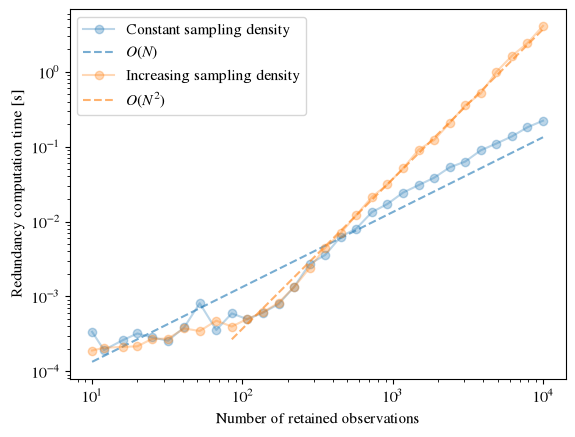

In [4]:
field = OccupancyField.from_yaml("../config/example_2d_config.yaml")

constant_benchmark   = Benchmark()
increasing_benchmark = Benchmark()

constant_benchmark.run(sample_range,
                       operation = field._redundancy_weights,
                       setup     = fixed_density_observations)

increasing_benchmark.run(sample_range,
                         operation = field._redundancy_weights,
                         setup     = fixed_extent_observations)


fig, ax = plt.subplots()

constant_benchmark.plot(ax,
                        label = "Constant sampling density",
                        color = "tab:blue")

increasing_benchmark.plot(ax,
                          label = "Increasing sampling density",
                          color = "tab:orange")

ax.set_xlabel("Number of retained observations")
ax.set_ylabel("Redundancy computation time [s]")

ax.legend()

plt.show()

## Observation Addition

The public field-update operation includes observation validation, temporal pruning, insertion into the retained observation set, and recomputation of redundancy weights.

The same constant- and increasing-density regimes are used to determine whether the scaling observed for sparse redundancy computation carries through to the complete field update.

Each timed addition is performed on a fresh field so that repeated measurements represent the same operation.

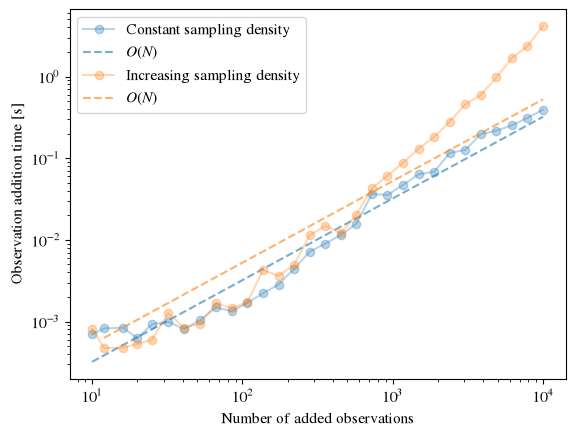

In [5]:
def setup_fixed_density(n):

    field        = OccupancyField.from_yaml("../config/example_2d_config.yaml")
    observations = fixed_density_observations(n)

    return field, observations


def setup_fixed_extent(n):

    field        = OccupancyField.from_yaml("../config/example_2d_config.yaml")
    observations = fixed_extent_observations(n)

    return field, observations


def add_observations(state):

    field, observations = state

    return field.add(observations)


constant_benchmark   = Benchmark()
increasing_benchmark = Benchmark()

constant_benchmark.run(sample_range,
                       operation = add_observations,
                       setup     = setup_fixed_density)

increasing_benchmark.run(sample_range,
                         operation = add_observations,
                         setup     = setup_fixed_extent)


fig, ax = plt.subplots()

constant_benchmark.plot(ax,
                        label = "Constant sampling density",
                        color = "tab:blue")

increasing_benchmark.plot(ax,
                          label = "Increasing sampling density",
                          color = "tab:orange")

ax.set_xlabel("Number of added observations")
ax.set_ylabel("Observation addition time [s]")

ax.legend()

plt.show()

## Query Scaling with Retained Observations

Field queries evaluate occupied and free evidence from retained observations at a supplied set of query locations.

For $N$ retained observations and $M$ query points, the current dense evidence evaluation forms observation-query interactions of size

$$
N\times M.
$$

To isolate scaling with field size, the number of query points is held fixed while the number of retained observations is varied. The field is populated before timing so that only query evaluation is measured.

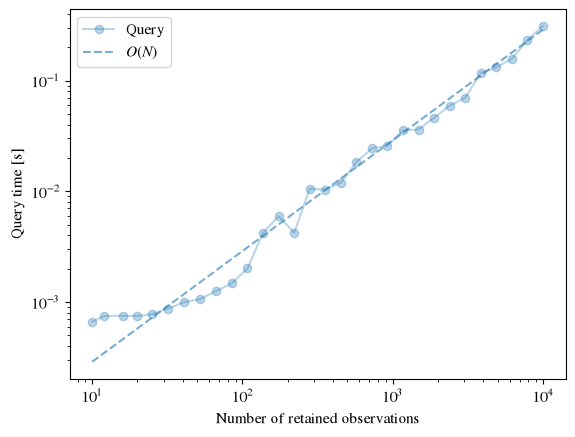

In [6]:
query_points = np.column_stack((np.linspace(0.0, 1.0, 100), np.full(100, 1.0)))


def setup_query(n):

    field = OccupancyField.from_yaml("../config/example_2d_config.yaml")
    field.add(fixed_density_observations(n))

    return field


def query_field(field):

    return field.query(query_points)


benchmark = Benchmark()

benchmark.run(sample_range,
              operation = query_field,
              setup     = setup_query)


fig, ax = plt.subplots()

benchmark.plot(ax,
               label = "Query",
               color = "tab:blue")

ax.set_xlabel("Number of retained observations")
ax.set_ylabel("Query time [s]")

ax.legend()

plt.show()

## Query Scaling with Evaluation Size

Query cost also depends on the number of locations evaluated simultaneously. To isolate this dependence, the retained field is held fixed while the number of query points, $M$, is varied.

Together with the preceding experiment, this characterises the two dimensions of the dense observation-query evaluation,

$$
T_{\mathrm{query}}=T(N,M),
$$

where $N$ is the number of retained observations and $M$ is the number of queried locations.

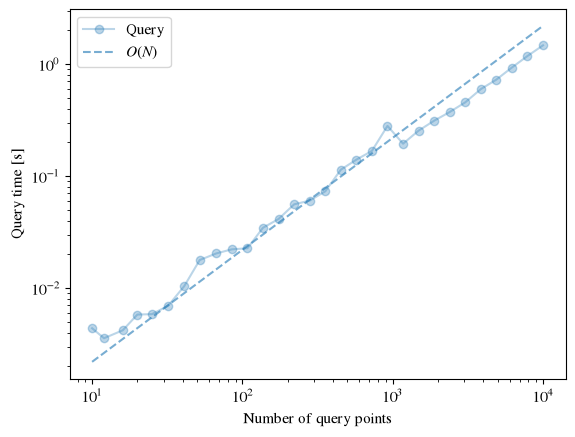

In [7]:
field = OccupancyField.from_yaml("../config/example_2d_config.yaml")
field.add(fixed_density_observations(1000))

benchmark = Benchmark()


def query_points(n):

    return np.column_stack((np.linspace(0.0, 1.0, n),
                            np.full(n, 1.0)))


benchmark.run(sample_range,
              operation = field.query,
              setup     = query_points)


fig, ax = plt.subplots()

benchmark.plot(ax,
               label = "Query",
               color = "tab:blue")

ax.set_xlabel("Number of query points")
ax.set_ylabel("Query time [s]")

ax.legend()

plt.show()